# ***Sales Data Analysis***

## 1. **Introduction**




The objective of this project is to analyze sales data using Python in order to understand sales performance, profitability, product performance, regional trends, and the impact of discounts.


## 2. **Business Objectives**

Analyze overall sales and profit performance.

Identify the best-performing categories and sub-categories.

Understand yearly and monthly sales trends.

Compare sales performance across regions.

Identify the top 10 best-selling products.

Investigate the relationship between discounts and profit.

Identify loss-making transactions and provide business recommendation






## 3. **Tools & libraries**

Python

Pandas

Matplotlib

Google Colab

NumPY

Seaborn

 ## 4. **Tools & Libraries + Data Loading**

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("My first Data Analysis project!")
print("All libraries are ready.")

My first Data Analysis project!
All libraries are ready.


In [56]:
import pandas as pd
url="https://raw.githubusercontent.com/sirine-amri/sales-dashboard-powerbi/main/data/Sample-Superstore.csv"
df = pd.read_csv(url, encoding="latin-1")
print("Dataset loaded successfully!")

Dataset loaded successfully!


## 5. **Data Understanding**

In [57]:
print("Rows and columns: ", df.shape)
display(df.head())

Rows and columns:  (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [59]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [60]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 6. **Data Quality & Preparation**

In [61]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
df.isnull().sum().sum()

np.int64(0)

In [64]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])


In [65]:
df[["Order Date", "Ship Date"]].dtypes

,0
Order Date,datetime64[ns]
Ship Date,datetime64[ns]


## 7. **KPIs**

In [66]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Profit Margin:", round(total_profit / total_sales * 100, 2), "%")

Total Sales: 2297200.86
Total Profit: 286397.02
Profit Margin: 12.47 %


## 8. **Category & Sub-Category Analysis**

In [67]:
sales_by_category = df.groupby('Category')['Sales'].sum()
profit_by_category = df.groupby('Category')['Profit'].sum()
print("Sales by Category:")
print(sales_by_category)
print("\nProfit by Category:")
print(profit_by_category)

Sales by Category:
Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64

Profit by Category:
Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


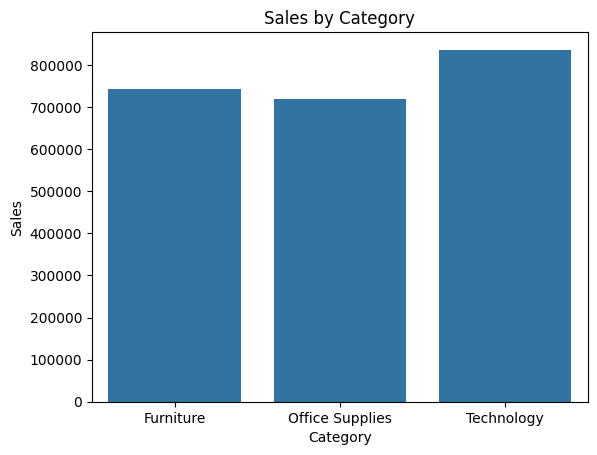

In [68]:
sns.barplot(
    x=sales_by_category.index,
    y=sales_by_category.values,
)
plt.xlabel('Category')
plt.ylabel('Sales')
plt.title('Sales by Category')
plt.show()

Thechnology leads in sales (\$836), followed by Furniture (\$742) and Office Supplies (\$719). The three categories are close in sales volume.

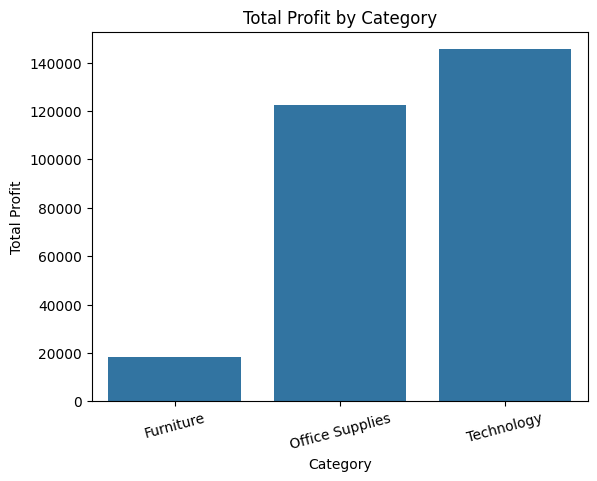

In [69]:
sns.barplot(
    x=profit_by_category.index,
    y=profit_by_category.values
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=15)
plt.show()

In [70]:
margin_by_category = (profit_by_category / sales_by_category * 100).round(2)
print("Profit margin (%) by Category:")
print(margin_by_category.sort_values())

Profit margin (%) by Category:
Category
Furniture           2.49
Office Supplies    17.04
Technology         17.40
dtype: float64


Thechnology (\$145K) and Office Supplies (\$122K) generate most of the profit. Furniture generates only \$18K despite \$742K in sales, which gives it a margin of just 2.5% versus about 17% for the other two categories.


In [71]:
sales_by_subcategory= (
    df.groupby("Sub-Category")["Sales"]
    .sum()
    .sort_values()
)

print(sales_by_subcategory)

Sub-Category
Fasteners        3024.2800
Labels          12486.3120
Envelopes       16476.4020
Art             27118.7920
Supplies        46673.5380
Paper           78479.2060
Furnishings     91705.1640
Appliances     107532.1610
Bookcases      114879.9963
Copiers        149528.0300
Accessories    167380.3180
Machines       189238.6310
Binders        203412.7330
Tables         206965.5320
Storage        223843.6080
Chairs         328449.1030
Phones         330007.0540
Name: Sales, dtype: float64


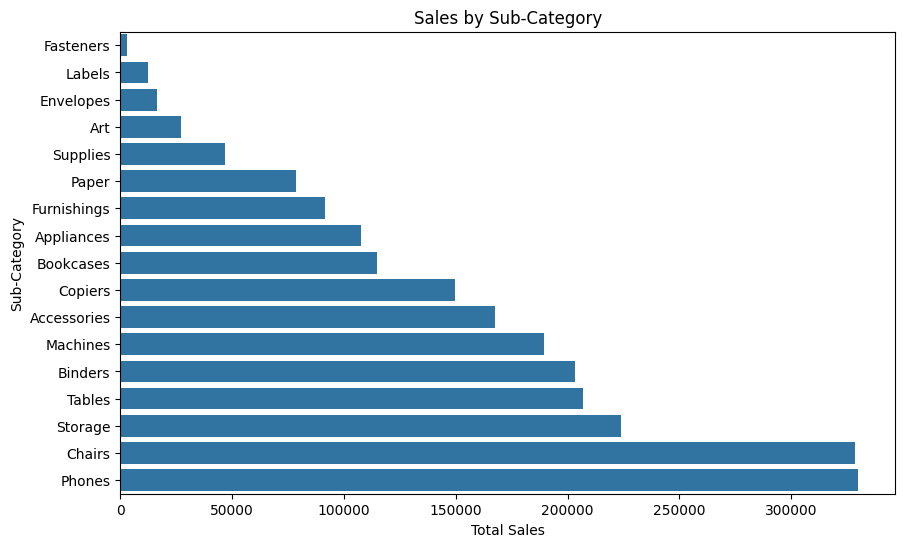

In [72]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=sales_by_subcategory.values,
    y=sales_by_subcategory.index
)

plt.title("Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")
plt.show()

Phones (\$330K) and Chairs (\$328K) are the topsellers, followed by Storage, Tables and Binders, Fasteners, Labels and Envelopes sell the least. Sales volume alone does not show which products are profitable .

In [73]:
profit_by_subcategory = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

print(profit_by_subcategory)

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64


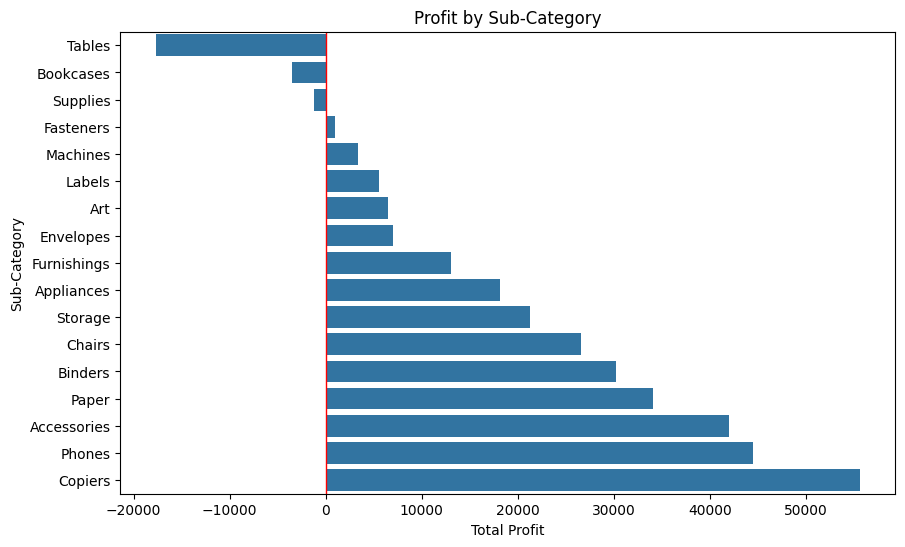

In [74]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=profit_by_subcategory.values,
    y=profit_by_subcategory.index
)

plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.axvline(0, color="red", linewidth=1)
plt.show()

Copies (\$55.6K) , Phones(\$44.5K) and Accessoires(\$41.9K)    contribute the most profit.Three sub-categories lose money overall: Tables (-\$17.7K), Bookcases (-\$3.5K) and Supplies(-\$1.2K).


,Sales,Profit,Margin %
Sub-Category,,,
Tables,206965.5320,-17725.4811,-8.56
Bookcases,114879.9963,-3472.5560,-3.02
Supplies,46673.5380,-1189.0995,-2.55
Machines,189238.6310,3384.7569,1.79
Chairs,328449.1030,26590.1663,8.10
Storage,223843.6080,21278.8264,9.51
Phones,330007.0540,44515.7306,13.49
Furnishings,91705.1640,13059.1436,14.24
Binders,203412.7330,30221.7633,14.86


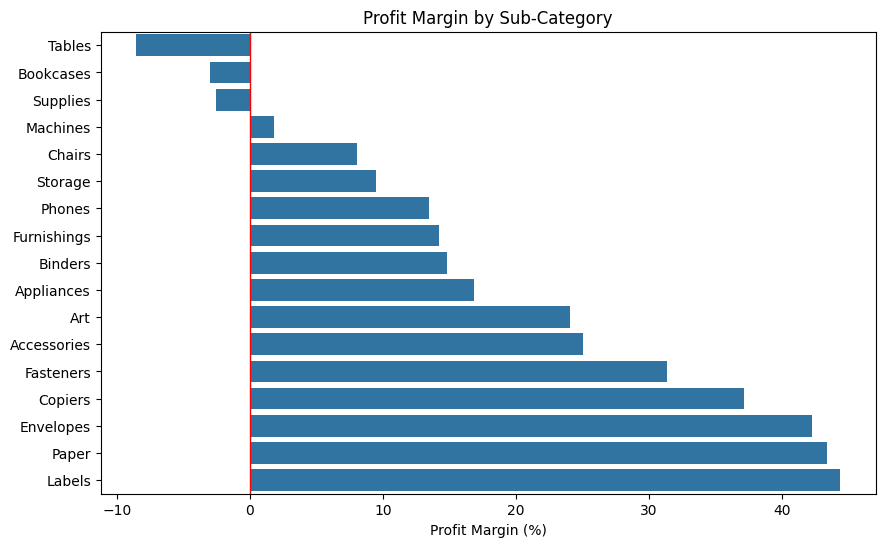

In [75]:
margin_by_subcat = df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
margin_by_subcat["Margin %"] = (margin_by_subcat["Profit"] / margin_by_subcat["Sales"] * 100).round(2)
margin_sorted = margin_by_subcat.sort_values("Margin %")
display(margin_sorted)

plt.figure(figsize=(10, 6))
sns.barplot(x=margin_sorted["Margin %"], y=margin_sorted.index)
plt.axvline(0, color="red", linewidth=1)
plt.title("Profit Margin by Sub-Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("")
plt.show()

Labels, Paper, Envelopes and Copiers have the highest margins(37-44%). Tables(-8.6%), Bookcases (-3.0%) and Supplies (-2.6%) have negative margins. Two big sellers earn little: Machines (\$189K in sales) has a 1.8% margin and Chairs (\$328K) only 8.1%.

## 9. **Discount Analysis**

In [76]:
bins = [-0.01, 0, 0.20, 0.40, 1.0]
labels = ["No discount", "1-20%", "21-40%", "40%+"]

df["Discount Band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

In [77]:
profit_by_band = df.groupby("Discount Band", observed=True)["Profit"].agg(
    avg_profit="mean",
    total_profit="sum",
    transactions="count"
).round(2)

print(profit_by_band)

               avg_profit  total_profit  transactions
Discount Band                                        
No discount         66.90     320987.60          4798
1-20%               26.50     100785.47          3803
21-40%             -77.86     -35817.47           460
40%+              -106.71     -99558.59           933


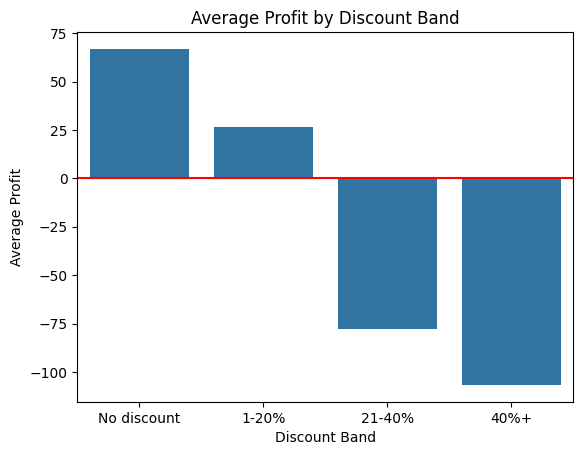

In [78]:
sns.barplot(x=profit_by_band.index, y=profit_by_band["avg_profit"])
plt.axhline(0, color="red")
plt.title("Average Profit by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Average Profit")
plt.show()

Average profit per transaction falls as discounts increase: +$66.90 with no discount and +\$26.50 at 1-20%, then it turns negative at 21-40% (-\$77.86) and 40%+ (-\$106.71).

## 10. **Yearly Sales & Profit**

In [79]:
df["Year"] = df["Order Date"].dt.year

sales_by_year = df.groupby("Year")["Sales"].sum()

print(sales_by_year.round(2))

Year
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26
Name: Sales, dtype: float64


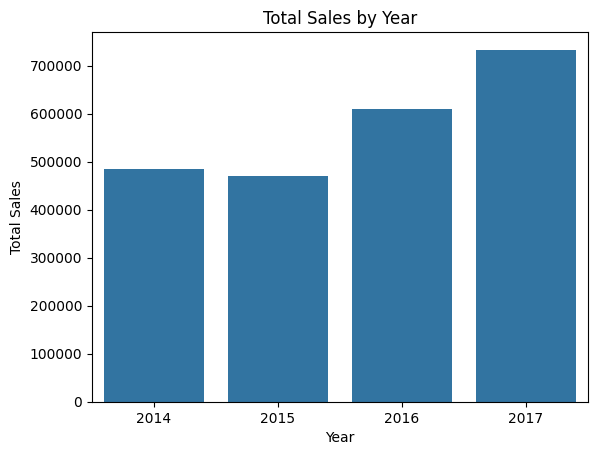

In [80]:
sns.barplot(x=sales_by_year.index, y=sales_by_year.values)

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.show()

Sales dipped slightly from 2014 (\$484K) to 2015 (\$471K), then grew strongly to \$609K in 2016 and \$733K in 2017, an increase of about 51% between 2014 and 2017.

In [81]:
profit_by_year = df.groupby("Year")["Profit"].sum()

print(profit_by_year.round(2))

Year
2014    49543.97
2015    61618.60
2016    81795.17
2017    93439.27
Name: Profit, dtype: float64


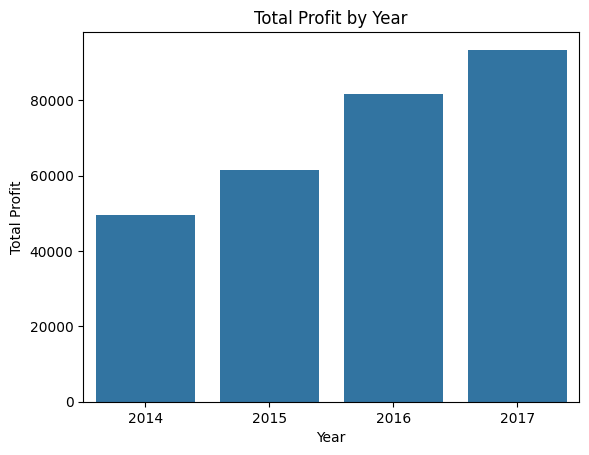

In [82]:
sns.barplot(x=profit_by_year.index, y=profit_by_year.values)

plt.title("Total Profit by Year")
plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.show()

Profit increased every year, from \$49.5K in 2014 to \$93.4K in 2017. Profit grew faster than sales: the Overall margin improved from about 10.2% in 2014 to about 12.7% in 2017.

## 11. **Monthly Sales Trends**

In [83]:
df['Month'] = df['Order Date'].dt.month
sales_by_month = df.groupby("Month")["Sales"].sum()
print(sales_by_month)

Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035
Name: Sales, dtype: float64


In [84]:
sales_by_month.idxmax()

np.int32(11)

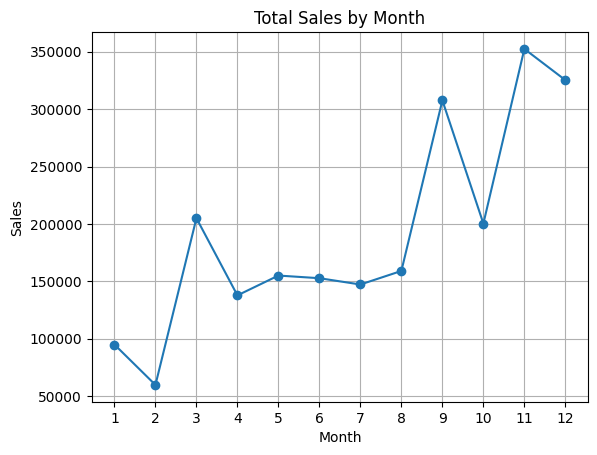

In [85]:
sales_by_month.plot(kind="line", marker="o")
plt.title("Total Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

Sales peak in November \$352K and December \$325K, with another peak in September \$308K. February is the weakest month \$60K, followed by January \$95K.

In [86]:
profit_by_month = df.groupby("Month")["Profit"].sum()
print(profit_by_month.round(2))

Month
1      9134.45
2     10294.61
3     28594.69
4     11587.44
5     22411.31
6     21285.80
7     13832.66
8     21776.94
9     36857.48
10    31784.04
11    35468.43
12    43369.19
Name: Profit, dtype: float64


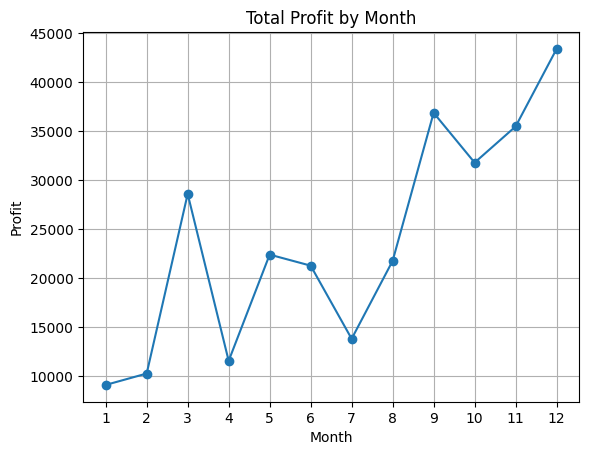

In [87]:
profit_by_month.plot(kind="line", marker="o")
plt.title("Total Profit by Month")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

Profit does not follow sales exactly.December is the most profitable month \$43.4K, followed by September \$36.5K, while January \$9.1K and February \$10.3K are the least profitable.

In [88]:
pivot_sales = df.pivot_table(
    values='Sales',
    index='Month',
    columns='Year',
    aggfunc='sum'
)

display(pivot_sales.round(2))

Year,2014,2015,2016,2017
Month,,,,
1,14236.90,18174.08,18542.49,43971.37
2,4519.89,11951.41,22978.82,20301.13
3,55691.01,38726.25,51715.88,58872.35
4,28295.34,34195.21,38750.04,36521.54
5,23648.29,30131.69,56987.73,44261.11
6,34595.13,24797.29,40344.53,52981.73
7,33946.39,28765.32,39261.96,45264.42
8,27909.47,36898.33,31115.37,63120.89
9,81777.35,64595.92,73410.02,87866.65


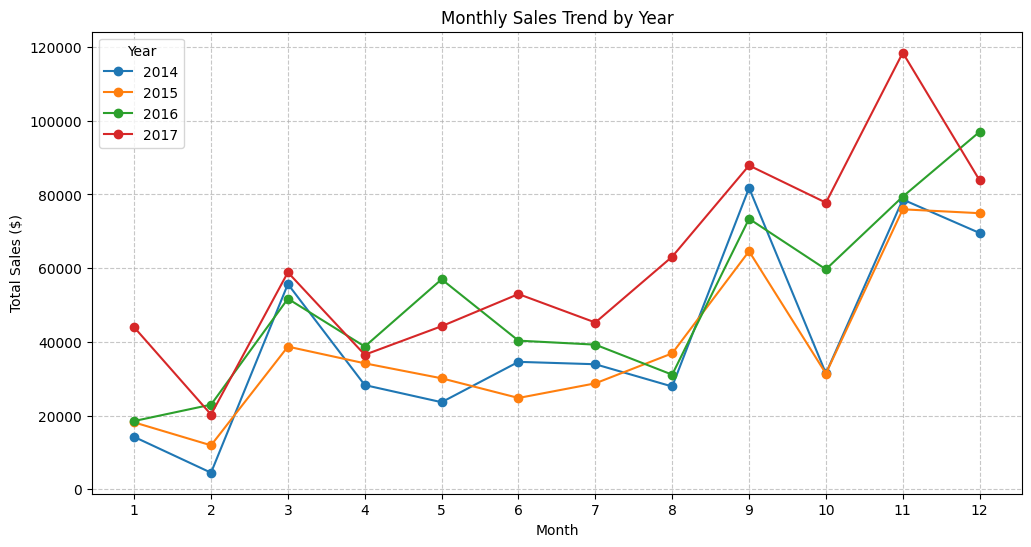

In [89]:
plt.figure(figsize=(12, 6))

pivot_sales.plot(kind='line', marker='o', ax=plt.gca())
plt.title('Monthly Sales Trend by Year')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Year')
plt.show()

The seasonal pattern repeats every year: September, November and December are the three strongest months in each of the four years, and Fbruary is the weakest month in most years. 2017 stands out with much higher sales in several months ( for exemple November reached \$118K), confirming real seasonality combined with overall growth.

## 12. **Regional Sales & Top Products**

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


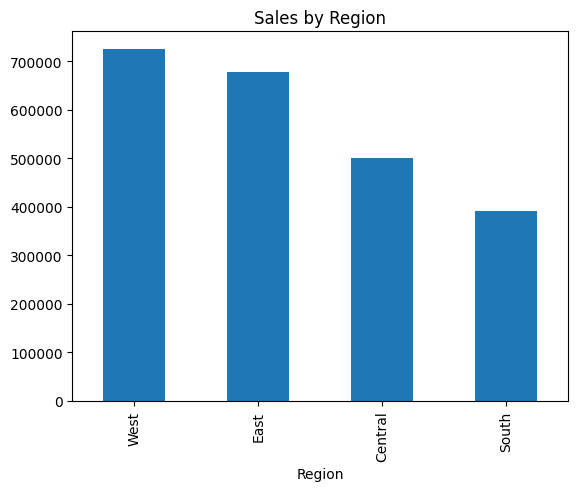

In [90]:
sales_by_region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(sales_by_region)
sales_by_region.plot(kind="bar")
plt.title("Sales by Region")
plt.show()

West \$725K and East \$679K leads in sales, ahead of central \$501K and South \$392K

In [91]:
region = df.groupby("Region")[["Sales", "Profit"]].sum()
region["Margin %"] = (region["Profit"] / region["Sales"] * 100).round(2)
display(region.sort_values("Margin %"))

,Sales,Profit,Margin %
Region,,,
Central,501239.8908,39706.3625,7.92
South,391721.9050,46749.4303,11.93
East,678781.2400,91522.7800,13.48
West,725457.8245,108418.4489,14.94


West has the best profit margin(14.9%), followed by East (13.5%) and South(11.9%).Central has the lowest margin (7.9%): it earns only \$39.7K in profit from \$501K in sales, less than South \$46.7K, which sells less.

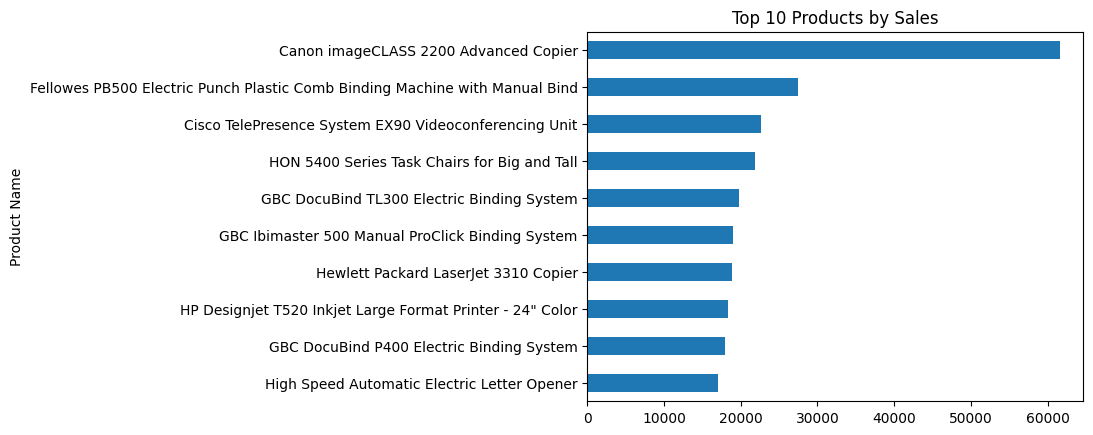

In [92]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales")
plt.show()

The Canon imageCLASS 2200 Advanced Copier is by far the best-selling product (about \$61K), well ahead of the fellowes PB500 binding machine (about \$27K) and the Cisco TelePresence System EX90 (about \$23K). The top 10 is dominated by oddice machines such as copiers,binding systems and printers. This chart shows sales only, not profit.

## 13. **Sales vs Profit & Loss Analysis**

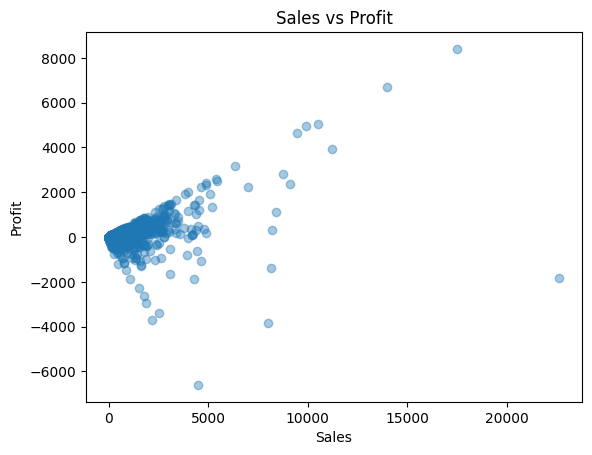

In [93]:
plt.scatter(df["Sales"], df["Profit"], alpha=0.4)
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

Most transactions are concentrated at low sales and low profit values, and higher sales generally come with higher profit. However, some transactions have negative profit, including a few with high sales, so high sales do not guarantee profitability. These loss-making transactions are investigated next.

In [94]:
losses = df[df["Profit"] < 0]

print("Number of loss-making transactions:", len(losses))
print("Number of loss-making orders:", losses["Order ID"].nunique())
print("Total loss:", round(losses["Profit"].sum(), 2))

losses[["Sales", "Discount", "Profit"]].sort_values(
    "Profit"
).head(10)

Number of loss-making transactions: 1871
Number of loss-making orders: 1318
Total loss: -156131.29


,Sales,Discount,Profit
7772,4499.985,0.7,-6599.9780
683,7999.980,0.5,-3839.9904
9774,2177.584,0.8,-3701.8928
3011,2549.985,0.7,-3399.9800
4991,1889.990,0.8,-2929.4845
3151,1799.994,0.7,-2639.9912
5310,1525.188,0.8,-2287.7820
9639,4297.644,0.4,-1862.3124
1199,1088.792,0.8,-1850.9464
2697,22638.480,0.5,-1811.0784


1.871 transactions (about 19% of all transactions) lose money, spread over 1.318 orders, for a total loss of \$156K. The 10 worst transactions all have a discount of 40% or more (up to 80%), which suggests discounts are a major factor.

## 13.1 **Loss by subcategory**

In [95]:
loss_by_subcat = (
    losses.groupby("Sub-Category")["Profit"]
    .agg(total_loss="sum", transactions="count")
    .sort_values("total_loss")
    .round(2)
)
print(loss_by_subcat)

              total_loss  transactions
Sub-Category                          
Binders        -38510.50           613
Tables         -32412.15           203
Machines       -30118.67            44
Bookcases      -12152.21           109
Chairs          -9880.84           235
Appliances      -8629.64            67
Phones          -7530.62           136
Furnishings     -6490.91           167
Storage         -6426.30           161
Supplies        -3015.62            33
Accessories      -930.63            91
Fasteners         -33.20            12


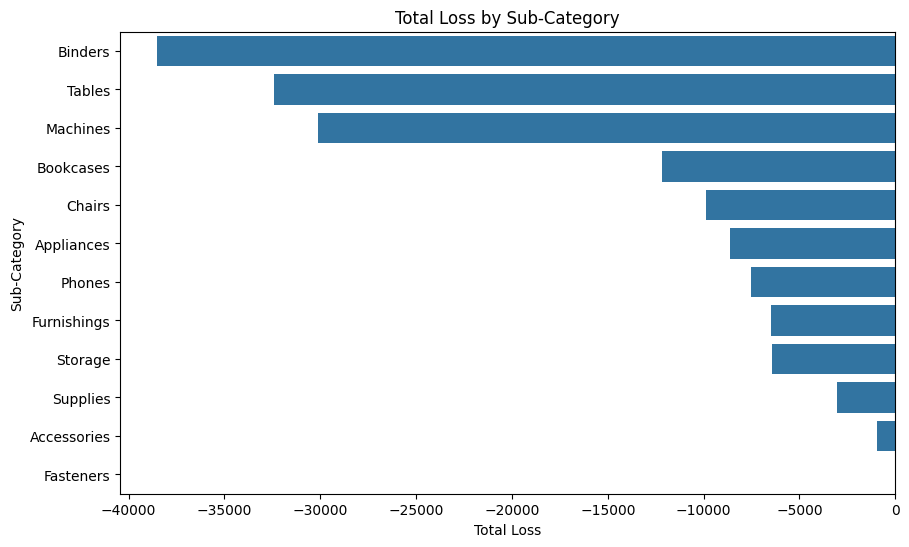

In [96]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=loss_by_subcat["total_loss"],
    y=loss_by_subcat.index
)
plt.title("Total Loss by Sub-Category")
plt.xlabel("Total Loss")
plt.ylabel("Sub-Category")
plt.show()

Binders -\$38.5K, Tables-\$30.1K account for the largest losses.The pattern differs:Binders lose money on many transactions (613) but remain profitable overall +\$30.2K, while Machines lose a lot in only (44) transactions.

## 13.2 **Loss by Region**

In [97]:
loss_by_region = (
    losses.groupby("Region")["Profit"]
    .agg(total_loss="sum", transactions="count")
    .sort_values("total_loss")
    .round(2)
)
print(loss_by_region)

         total_loss  transactions
Region                           
Central   -56314.88           741
East      -49590.61           553
South     -27504.83           259
West      -22720.96           318


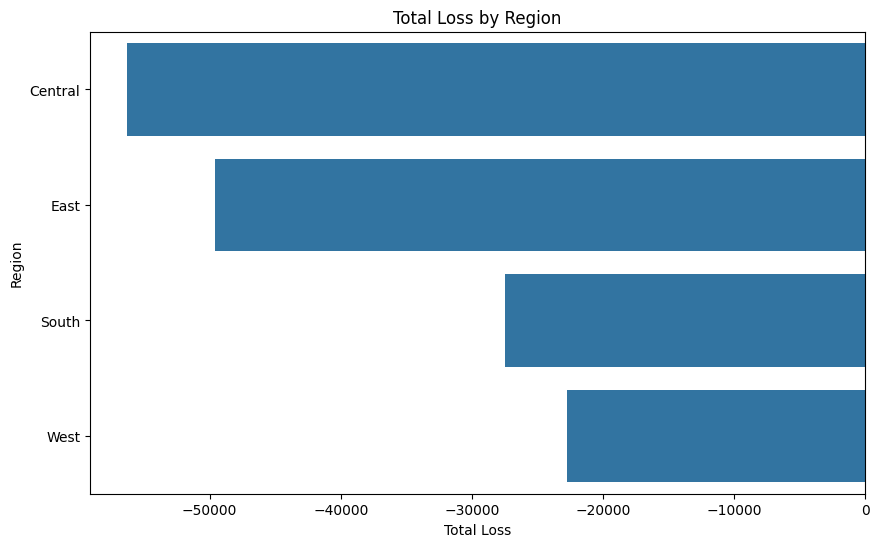

In [98]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=loss_by_region["total_loss"],
    y=loss_by_region.index
)
plt.title("Total Loss by Region")
plt.xlabel("Total Loss")
plt.ylabel("Region")
plt.show()

Central has the largest losses (-\$56.3K , 741 transactions), followed by East (-\$49.6K).West has the smallest losses(-\$22.7K), which is consistent with its better  margin.

## 13.3 **Loss by Discount Band**

In [99]:
loss_by_band = (
    losses.groupby("Discount Band", observed=True)["Profit"]
    .agg(total_loss="sum", transactions="count")
    .round(2)
)
print(loss_by_band)

               total_loss  transactions
Discount Band                          
1-20%           -17616.04           523
21-40%          -38956.65           415
40%+            -99558.59           933


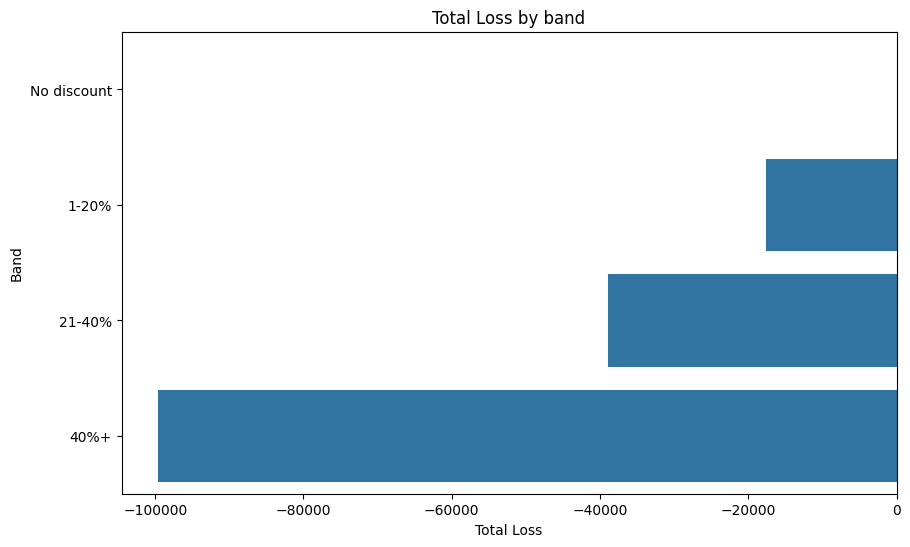

In [100]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x=loss_by_band["total_loss"],
    y=loss_by_band.index
)
plt.title("Total Loss by band")
plt.xlabel("Total Loss")
plt.ylabel("Band")
plt.show()

The 40%+ band accounts for most of the losses -\$99.6K , and all 933 transactions in this band lose money. The 21-40% band follows (-\$39.0K,415 of its 460 transactions), while losses at 1-20% are much smaller (-\$17.6K).No transactions without a discount loses money.

## 14. **Key Findings & Recommendations**

**Findings**
 1. **Overall:**  total sales of \$230M  and total profit of \$286K (12.5% margin).
 2. **Furniture is the weak category:** \$742K in sales but only a 2.5% margin, versus about 17% for Office Supplies and Technology. Tables (-\$17.7K),Bookcases -\$3.5K and Supplies -\$1.2K lose money overall, Machines sells \$189K for a 1.8% margin .
 3. **Discounts are strongly linked to losses:** average profit is +\$66.90 with no discoount and +\$26.50 at 1-20%, but -\$77.86 at 21-40% and -\$106.71 above 40%.All 933 transactions above 40% discount lose money -\$99.6K.
 4. **Where losses come from:** 1.871 transactions (about 19%) lose money, for -\$156K in total.The largest losses are in Binders, Tables and Machines, and in the Central region (-\$56.3K).
 5. **Regions:** Central has the lowest margin (7.9%) versus 14.9% for West.
 6. **Growth:** sales grew from \$484K(2014) to \$733K(2017) and profit from \$49.5K to \$93.4K, improving the margin from about 10.2% to 12.7%.
 7. **Seasonality:** September,November and Decemeber are the strongest months in every year; **February** is the weakest.

**Recommendations**
 1. Review the discount policy: avoid discounts above 20%, and especially above 40%.
 2. Re-examine pricing and discounting for Tables, Bookcases and Machines.
 3. Investigate the Central region, which has the lowest margin and the largest losses.
 4. Plan stock and campaigns around September and the November-December peak.

In [101]:

# Export the cleaned dataset for Power BI
df.to_csv("sales_cleaned.csv", index=False)

# Download the file
from google.colab import files
files.download("sales_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>